# Vulnerability Landscape Report

Build a quarterly threat overview from a multi-year NVD library.
`CacheBuilder.ensure()` bootstraps the data once; the rest of the
notebook works directly with `VulnDataset`.

In [ ]:
from vulnflow import VulnDataset
from vulnflow.helpers import CacheBuilder

# Bootstrap — only downloads if missing or stale
CacheBuilder(years=[2024, 2025]).ensure("../data/library.parquet", max_age="7d")

# Load directly from disk for the rest of the notebook
ds = VulnDataset.from_parquet("../data/library.parquet")
print(f"{len(ds):,} records, {len(ds.columns)} columns")

## Yearly CVE Growth

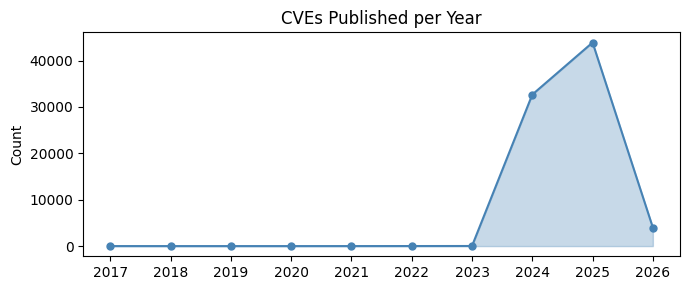

In [3]:
import matplotlib.pyplot as plt

yearly = ds.count_by("year")

fig, ax = plt.subplots(figsize=(7, 3))
ax.fill_between(yearly["year"], yearly["count"], alpha=0.3, color="steelblue")
ax.plot(yearly["year"], yearly["count"], marker="o", color="steelblue", markersize=5)
ax.set_title("CVEs Published per Year")
ax.set_ylabel("Count")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

## Severity Evolution

Stacked bar showing how the severity mix changes year over year.

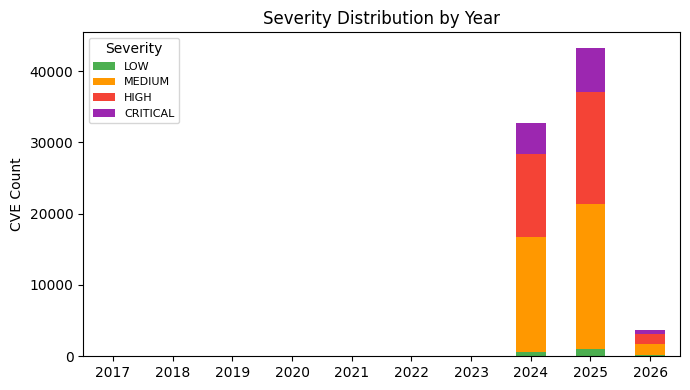

In [4]:
import pandas as pd

df = ds.to_pandas()
df["year"] = df["nvd_published_at"].dt.year

severity_order = ["LOW", "MEDIUM", "HIGH", "CRITICAL"]
colors = {"LOW": "#4caf50", "MEDIUM": "#ff9800", "HIGH": "#f44336", "CRITICAL": "#9c27b0"}

pivot = (
    df.groupby(["year", "cvss_base_severity"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=severity_order, fill_value=0)
)

fig, ax = plt.subplots(figsize=(7, 4))
pivot.plot.bar(stacked=True, ax=ax, color=[colors[s] for s in pivot.columns])
ax.set_title("Severity Distribution by Year")
ax.set_ylabel("CVE Count")
ax.set_xlabel("")
ax.legend(title="Severity", fontsize=8)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Top Weakness Types

Most common CWE categories.

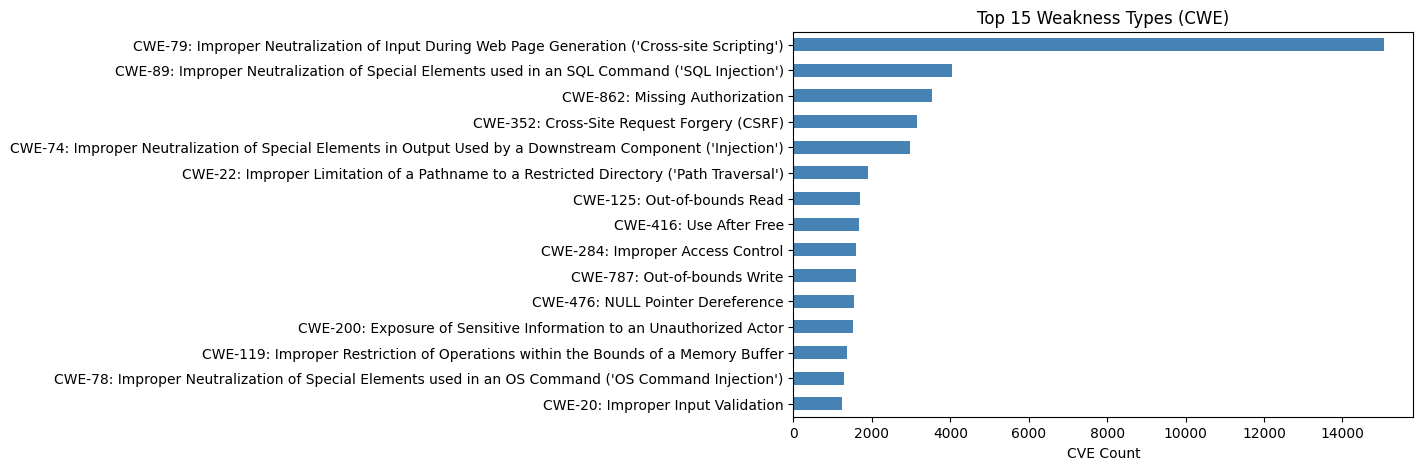

In [5]:
cwe_df = df.dropna(subset=["cwe_id", "cwe_name"])
cwe_df = cwe_df[cwe_df["cwe_id"] != "NVD-CWE-noinfo"]

# Combine ID + name for readable labels
cwe_df = cwe_df.copy()
cwe_df["cwe_label"] = cwe_df["cwe_id"] + ": " + cwe_df["cwe_name"]

top_cwes = cwe_df["cwe_label"].value_counts().head(15)

fig, ax = plt.subplots(figsize=(8, 5))
top_cwes.plot.barh(ax=ax, color="steelblue")
ax.set_title("Top 15 Weakness Types (CWE)")
ax.set_xlabel("CVE Count")
ax.set_ylabel("")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## EPSS vs CVSS Risk Quadrant

Log-scale EPSS axis with KEV overlay.

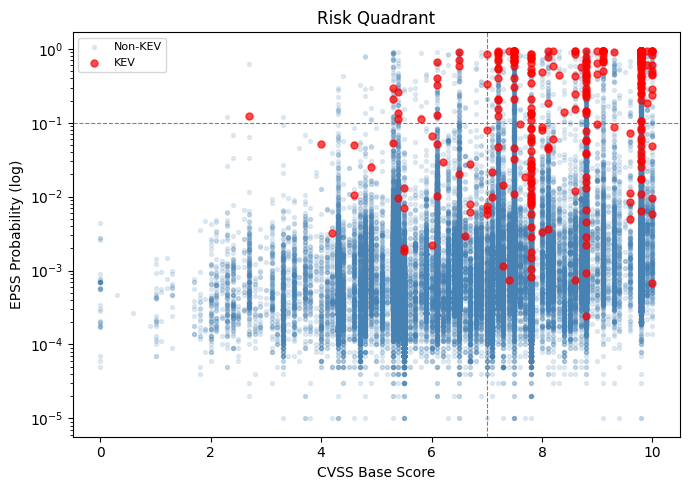

In [6]:
plot_df = df.dropna(subset=["cvss_base_score", "epss_probability"])
plot_df = plot_df[plot_df["epss_probability"] > 0].copy()

fig, ax = plt.subplots(figsize=(7, 5))

non_kev = plot_df[plot_df["is_kev"] != True]  # noqa: E712
kev_pts = plot_df[plot_df["is_kev"] == True]  # noqa: E712

ax.scatter(non_kev["cvss_base_score"], non_kev["epss_probability"],
           alpha=0.15, s=8, color="steelblue", label="Non-KEV")
ax.scatter(kev_pts["cvss_base_score"], kev_pts["epss_probability"],
           alpha=0.7, s=25, color="red", label="KEV", zorder=5)

ax.axvline(7, color="grey", linestyle="--", linewidth=0.8)
ax.axhline(0.1, color="grey", linestyle="--", linewidth=0.8)
ax.set_yscale("log")
ax.set_xlabel("CVSS Base Score")
ax.set_ylabel("EPSS Probability (log)")
ax.set_title("Risk Quadrant")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## KEV Statistics

In [ ]:
kev = df[df["is_kev"] == True]  # noqa: E712

print(f"Total KEV entries: {len(kev):,}")

if len(kev) > 0:
    ransomware = kev[kev["kev_ransomware"] == True]  # noqa: E712
    print(f"Ransomware-linked: {len(ransomware):,} ({100 * len(ransomware) / len(kev):.0f}%)")

    print("\nKEV severity distribution:")
    print(kev["cvss_base_severity"].value_counts().to_string())

    if "kev_date_added" in kev.columns:
        kev_dates = pd.to_datetime(kev["kev_date_added"], errors="coerce")
        monthly = kev_dates.dt.to_period("M").value_counts().sort_index().tail(6)
        print(f"\nRecent monthly KEV additions:")
        for period, count in monthly.items():
            print(f"  {period}: {count}")
else:
    print("No KEV entries in dataset.")

## Monthly Trend

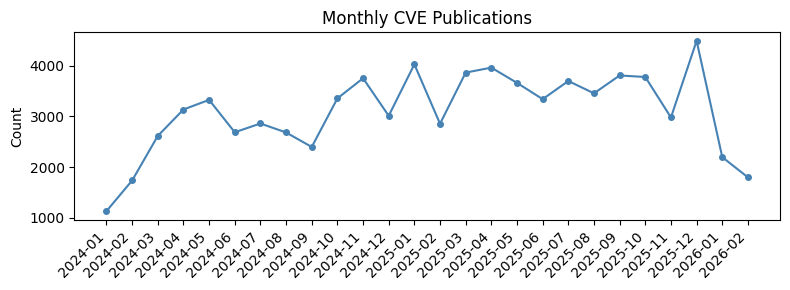

In [8]:
monthly = ds.count_by("month", start="2024-01-01")

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(monthly["month"].astype(str), monthly["count"], marker="o", markersize=4, color="steelblue")
ax.set_title("Monthly CVE Publications")
ax.set_ylabel("Count")
ax.set_xlabel("")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Top Vendors

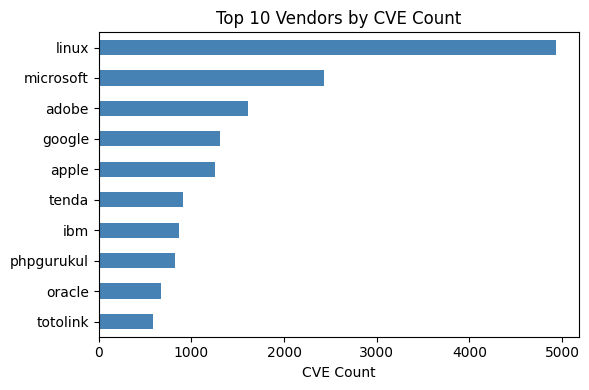

In [9]:
vendors = (
    df["cpe_vendor"]
    .dropna()
    .value_counts()
    .head(10)
)

fig, ax = plt.subplots(figsize=(6, 4))
vendors.plot.barh(ax=ax, color="steelblue")
ax.set_title("Top 10 Vendors by CVE Count")
ax.set_xlabel("CVE Count")
ax.set_ylabel("")
ax.invert_yaxis()
plt.tight_layout()
plt.show()